In [9]:
!pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

In [11]:
df = pd.read_csv("Online Retail.csv")

print(df.head())
print(df.shape)

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  01/12/10 08:26       2.55     17850.0  United Kingdom  
1  01/12/10 08:26       3.39     17850.0  United Kingdom  
2  01/12/10 08:26       2.75     17850.0  United Kingdom  
3  01/12/10 08:26       3.39     17850.0  United Kingdom  
4  01/12/10 08:26       3.39     17850.0  United Kingdom  
(541909, 8)


In [12]:
print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Rows:")
print(df.duplicated().sum())

df = df.drop_duplicates()

print("After Cleaning:")
print(df.shape)

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Duplicate Rows:
5268
After Cleaning:
(536641, 8)


In [39]:
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

print(df["InvoiceDate"].dtype)

datetime64[ns]


In [40]:
df["InvoiceNo"] = df["InvoiceNo"].astype(str)

df["is_cancelled"] = (
    df["InvoiceNo"].str.startswith("C").astype(int)
)

df["month"] = df["InvoiceDate"].dt.month

df["hour"] = df["InvoiceDate"].dt.hour

df["abs_quantity"] = df["Quantity"].abs()

print(df.head())
print("Feature engineering completed!")

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  is_cancelled  \
0 2010-01-12 08:26:00       2.55     17850.0  United Kingdom             0   
1 2010-01-12 08:26:00       3.39     17850.0  United Kingdom             0   
2 2010-01-12 08:26:00       2.75     17850.0  United Kingdom             0   
3 2010-01-12 08:26:00       3.39     17850.0  United Kingdom             0   
4 2010-01-12 08:26:00       3.39     17850.0  United Kingdom             0   

   month  hour  abs_quantity Investigation_Flag  
0      1     8             6             Normal 

# Convert product rows into invoice-level records

In [41]:
invoice_data = df.groupby("InvoiceNo").agg(

    line_count=("StockCode", "size"),

    total_abs_quantity=("abs_quantity", "sum"),

    average_unit_price=("UnitPrice", "mean"),

    unique_products=("StockCode", "nunique"),

    month=("month", "first"),

    hour=("hour", "first"),

    country=("Country", "first"),

    is_cancelled=("is_cancelled", "first")

).reset_index()

print(invoice_data.head())

print("Total Invoices:", len(invoice_data))

  InvoiceNo  line_count  total_abs_quantity  average_unit_price  \
0    536365           7                  40            3.910000   
1    536366           2                  12            1.850000   
2    536367          12                  83            4.853333   
3    536368           4                  15            4.775000   
4    536369           1                   3            5.950000   

   unique_products  month  hour         country  is_cancelled  
0                7      1     8  United Kingdom             0  
1                2      1     8  United Kingdom             0  
2               12      1     8  United Kingdom             0  
3                4      1     8  United Kingdom             0  
4                1      1     8  United Kingdom             0  
Total Invoices: 25900


In [42]:
X = invoice_data[[
    "line_count",
    "total_abs_quantity",
    "average_unit_price",
    "unique_products",
    "month",
    "hour",
    "country"
]]

y = invoice_data["is_cancelled"]

print("Features:", X.shape)
print("Target:", y.shape)

print(y.value_counts())

Features: (25900, 7)
Target: (25900,)
is_cancelled
0    22064
1     3836
Name: count, dtype: int64


In [43]:
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y

)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (20720, 7)
Testing Data: (5180, 7)


In [44]:
numeric_features = [
    "line_count",
    "total_abs_quantity",
    "average_unit_price",
    "unique_products",
    "month",
    "hour"
]

categorical_features = ["country"]

preprocessor = ColumnTransformer([

    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),

    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)

])

In [45]:
model = Pipeline([

    ("preprocessor", preprocessor),

    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))

])

model.fit(X_train, y_train)

print("Model Training Completed!")

Model Training Completed!


In [20]:
y_pred = model.predict(X_test)

print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

print("\nConfusion Matrix:")

print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7349420849420849

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.70      0.82      4413
           1       0.35      0.93      0.51       767

    accuracy                           0.73      5180
   macro avg       0.67      0.82      0.66      5180
weighted avg       0.89      0.73      0.77      5180


Confusion Matrix:
[[3090 1323]
 [  50  717]]


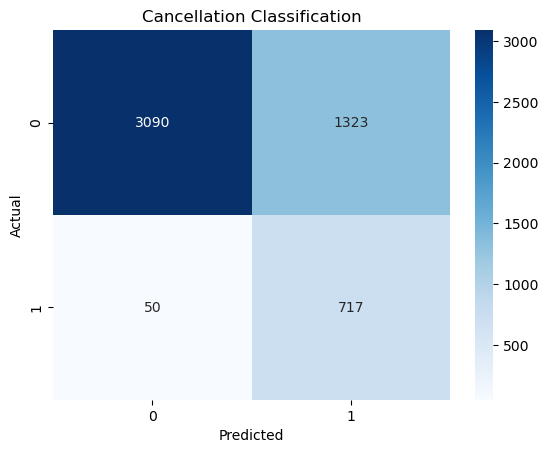

In [46]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Cancellation Classification")

plt.show()

In [47]:

import joblib

joblib.dump(model, "cancellation_model.pkl")

print("Model saved successfully!")


Model saved successfully!


In [48]:
returns = df[df["Quantity"] < 0].copy()

print("Total negative quantity records:",
      len(returns))

print("\nTop 10 products with negative quantities:")

print(
    returns.groupby("Description")["Quantity"]
    .count()
    .sort_values(ascending=False)
    .head(10)
)


Total negative quantity records: 10587

Top 10 products with negative quantities:
Description
Manual                               244
REGENCY CAKESTAND 3 TIER             180
POSTAGE                              126
check                                120
JAM MAKING SET WITH JARS              87
Discount                              77
SET OF 3 CAKE TINS PANTRY DESIGN      73
SAMPLES                               60
STRAWBERRY CERAMIC TRINKET BOX        54
ROSES REGENCY TEACUP AND SAUCER       54
Name: Quantity, dtype: int64


# Identify return-related transactions

In [49]:
returns = df[df["Quantity"] < 0].copy() # identifies rrecords with negative quantity and creates seperate date frame

print("Total Return-Related Records:", len(returns))# stores data for analysis

print("\nSample Records:")
print(returns.head())

Total Return-Related Records: 10587

Sample Records:
    InvoiceNo StockCode                       Description  Quantity  \
141   C536379         D                          Discount        -1   
154   C536383    35004C   SET OF 3 COLOURED  FLYING DUCKS        -1   
235   C536391     22556    PLASTERS IN TIN CIRCUS PARADE        -12   
236   C536391     21984  PACK OF 12 PINK PAISLEY TISSUES        -24   
237   C536391     21983  PACK OF 12 BLUE PAISLEY TISSUES        -24   

            InvoiceDate  UnitPrice  CustomerID         Country  is_cancelled  \
141 2010-01-12 09:41:00      27.50     14527.0  United Kingdom             1   
154 2010-01-12 09:49:00       4.65     15311.0  United Kingdom             1   
235 2010-01-12 10:24:00       1.65     17548.0  United Kingdom             1   
236 2010-01-12 10:24:00       0.29     17548.0  United Kingdom             1   
237 2010-01-12 10:24:00       0.29     17548.0  United Kingdom             1   

     month  hour  abs_quantity Investig

In [50]:
# most frequently appeared products in negative quantity transactions
top_products = (
    returns.groupby("Description")["Quantity"]
    .count()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Description
Manual                               244
REGENCY CAKESTAND 3 TIER             180
POSTAGE                              126
check                                120
JAM MAKING SET WITH JARS              87
Discount                              77
SET OF 3 CAKE TINS PANTRY DESIGN      73
SAMPLES                               60
STRAWBERRY CERAMIC TRINKET BOX        54
ROSES REGENCY TEACUP AND SAUCER       54
Name: Quantity, dtype: int64


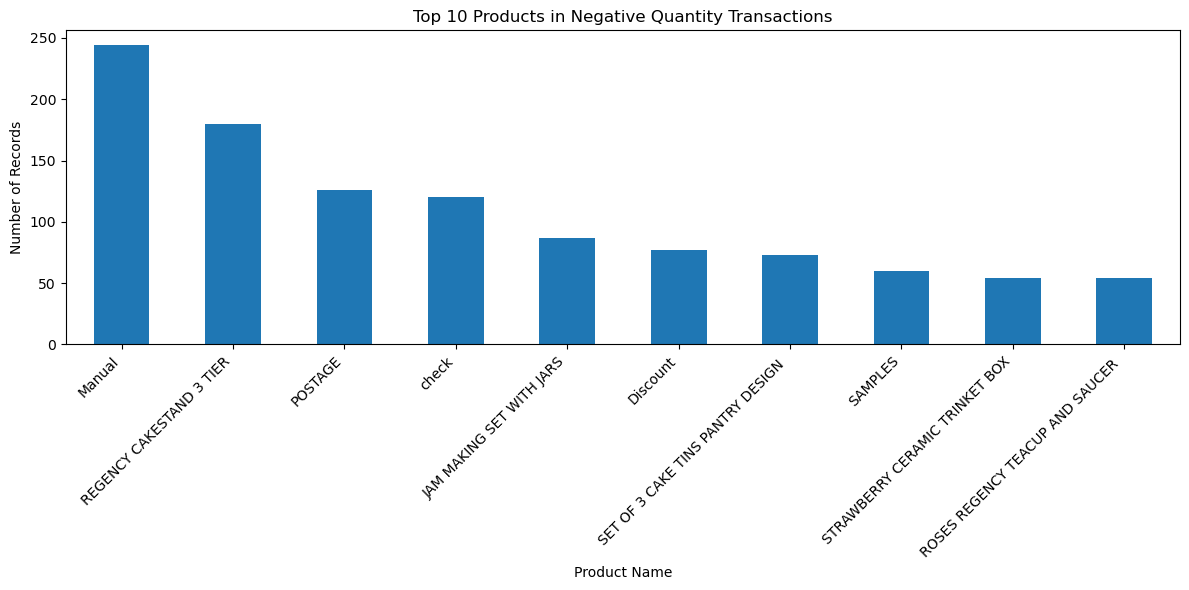

In [51]:
plt.figure(figsize=(12, 6))

top_products.plot(kind="bar")

plt.title("Top 10 Products in Negative Quantity Transactions")

plt.xlabel("Product Name")
plt.ylabel("Number of Records")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [52]:
returns["Month"] = returns["InvoiceDate"].dt.month

monthly_returns = returns.groupby("Month").size()

print(monthly_returns)

Month
1      845
2      539
3      824
4      712
5      778
6     1178
7     1009
8      896
9      957
10    1058
11    1096
12     695
dtype: int64


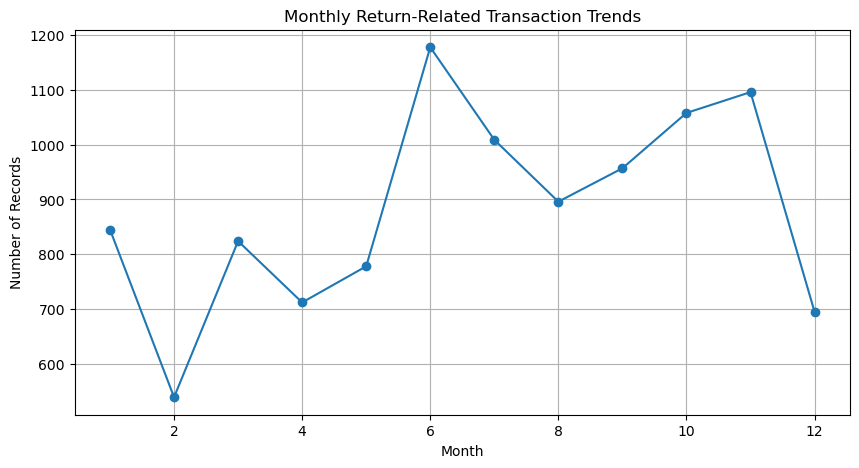

In [54]:
plt.figure(figsize=(10, 5))

monthly_returns.plot(kind="line", marker="o")

plt.title("Monthly Return-Related Transaction Trends")

plt.xlabel("Month")
plt.ylabel("Number of Records")

plt.grid(True)

plt.show()

In [29]:
country_returns = (
    returns.groupby("Country")["Quantity"]
    .count()
    .sort_values(ascending=False)
    .head(10)
)

print(country_returns)

Country
United Kingdom    9157
Germany            453
EIRE               301
France             148
USA                112
Australia           74
Spain               48
Italy               45
Belgium             38
Japan               37
Name: Quantity, dtype: int64


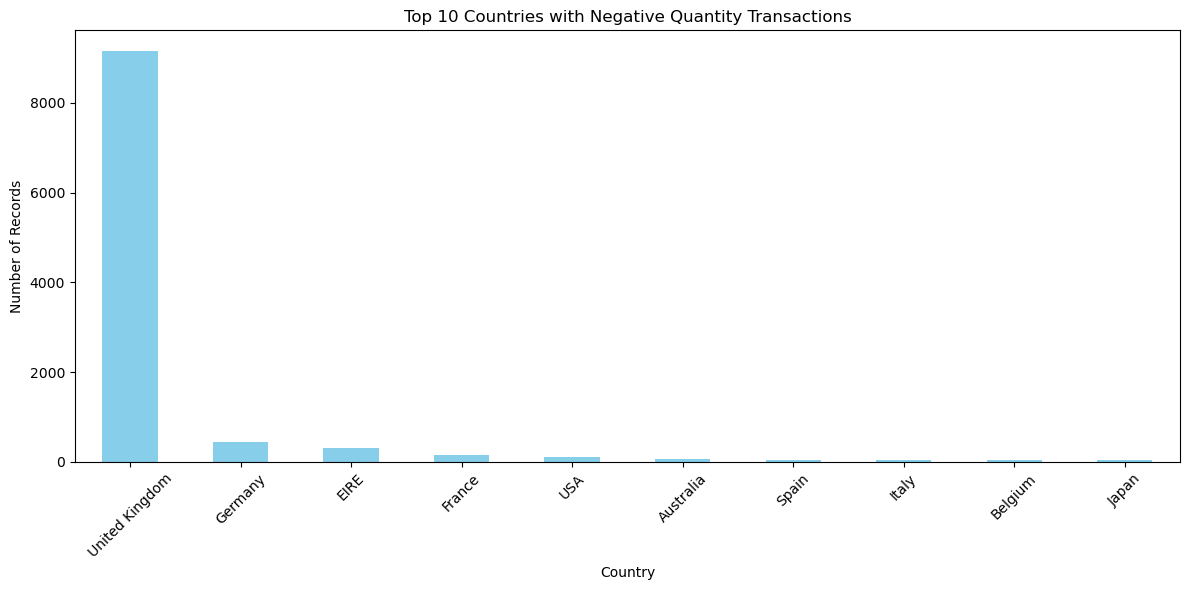

In [55]:
plt.figure(figsize=(12, 6))

country_returns.plot(kind="bar", color="skyblue")

plt.title("Top 10 Countries with Negative Quantity Transactions")

plt.xlabel("Country")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [31]:
returns["Return_Value"] = (
    returns["Quantity"].abs() * returns["UnitPrice"]
)

print("Total Negative Transaction Value:")

print(returns["Return_Value"].sum())

Total Negative Transaction Value:
893979.73


# Compare cancellations and other negative quantities

In [32]:
returns["Transaction_Type"] = np.where(
    returns["InvoiceNo"].astype(str).str.startswith("C"),
    "Cancellation Related",
    "Other Negative Quantity"
)

print(returns["Transaction_Type"].value_counts())

Transaction_Type
Cancellation Related       9251
Other Negative Quantity    1336
Name: count, dtype: int64


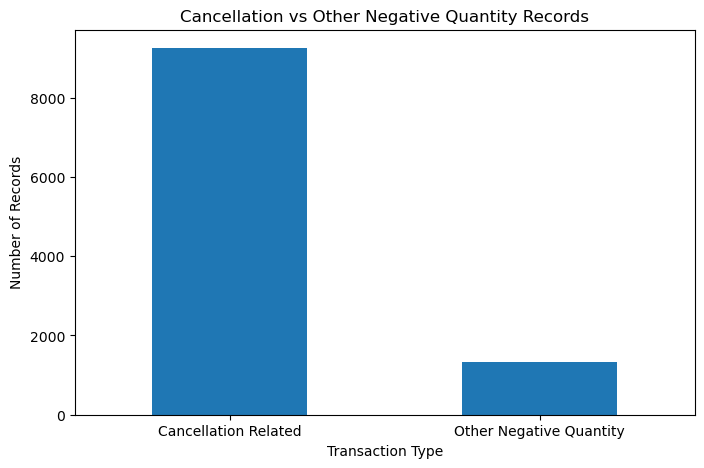

In [61]:
returns["Transaction_Type"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Cancellation vs Other Negative Quantity Records")

plt.xlabel("Transaction Type")
plt.ylabel("Number of Records")

plt.xticks(rotation=0)

plt.show()

In [59]:
print(returns.columns.tolist())

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'is_cancelled', 'month', 'hour', 'abs_quantity', 'Investigation_Flag', 'Month']


In [60]:
returns = df[df["Quantity"] < 0].copy()

returns["Transaction_Type"] = returns["is_cancelled"].map({
    1: "Cancellation Related",
    0: "Other Negative Quantity"
})

print(returns["Transaction_Type"].value_counts())

Transaction_Type
Cancellation Related       9251
Other Negative Quantity    1336
Name: count, dtype: int64


# Customer and Product Pattern Summaries

In [34]:
customer_data = df[df["CustomerID"].notna()].copy()

customer_summary = customer_data.groupby("CustomerID").agg(

    total_invoices=("InvoiceNo", "nunique"),

    total_products=("Quantity", "sum"),

    negative_records=("Quantity", lambda x: (x < 0).sum()),

    total_spending=(
        "Quantity",
        lambda x: 0
    )

).reset_index()

customer_summary["total_spending"] = (
    customer_data.assign(
        value=customer_data["Quantity"] * customer_data["UnitPrice"]
    )
    .groupby("CustomerID")["value"]
    .sum()
    .values
)

customer_summary = customer_summary.sort_values(
    "negative_records",
    ascending=False
)

print(customer_summary.head(10))

      CustomerID  total_invoices  total_products  negative_records  \
1895     14911.0             248           77155               226   
4042     17841.0             169           22628               136   
3801     17511.0              46           63012               113   
2192     15311.0             118           37673               112   
213      12607.0               2               0               101   
1523     14410.0              15             290                92   
1078     13798.0              63           23515                89   
1674     14606.0             128            5941                82   
587      13113.0              40            2594                79   
100      12471.0              49            7953                71   

      total_spending  
1895    1.324587e+05  
4042    3.986905e+04  
3801    8.812538e+04  
2192    5.928419e+04  
213     3.552714e-15  
1523    5.734500e+02  
1078    3.635287e+04  
1674    1.163335e+04  
587     1.051000e+04  

In [35]:
product_summary = df.groupby("Description").agg(

    total_records=("InvoiceNo", "count"),

    total_quantity=("Quantity", "sum"),

    negative_records=("Quantity", lambda x: (x < 0).sum())

).reset_index()

product_summary = product_summary.sort_values(
    "negative_records",
    ascending=False
)

print(product_summary.head(10))

                            Description  total_records  total_quantity  \
2246                             Manual            567            2925   
2915           REGENCY CAKESTAND 3 TIER           2189           13007   
2753                            POSTAGE           1252            3003   
4116                              check            159          -12030   
1833           JAM MAKING SET WITH JARS           1221            8459   
1126                           Discount             77           -1194   
3195  SET OF 3 CAKE TINS PANTRY DESIGN            1465            7329   
3059                            SAMPLES             62             -58   
3013   ROSES REGENCY TEACUP AND SAUCER            1128            9428   
3555     STRAWBERRY CERAMIC TRINKET BOX            765           10112   

      negative_records  
2246               244  
2915               180  
2753               126  
4116               120  
1833                87  
1126                77  
3195      

In [36]:
df["Investigation_Flag"] = np.where(

    (df["InvoiceNo"].astype(str).str.startswith("C")) |
    (df["Quantity"] < 0) |
    (df["UnitPrice"] <= 0),

    "Investigate",
    "Normal"

)

print(df["Investigation_Flag"].value_counts())

Investigation_Flag
Normal         524878
Investigate     11763
Name: count, dtype: int64


In [37]:
flagged_records = df[
    df["Investigation_Flag"] == "Investigate"
]

print(flagged_records.head(20))

print("Total Flagged Records:", len(flagged_records))

     InvoiceNo StockCode                          Description  Quantity  \
141    C536379         D                             Discount        -1   
154    C536383    35004C      SET OF 3 COLOURED  FLYING DUCKS        -1   
235    C536391     22556       PLASTERS IN TIN CIRCUS PARADE        -12   
236    C536391     21984     PACK OF 12 PINK PAISLEY TISSUES        -24   
237    C536391     21983     PACK OF 12 BLUE PAISLEY TISSUES        -24   
238    C536391     21980    PACK OF 12 RED RETROSPOT TISSUES        -24   
239    C536391     21484          CHICK GREY HOT WATER BOTTLE       -12   
240    C536391     22557     PLASTERS IN TIN VINTAGE PAISLEY        -12   
241    C536391     22553               PLASTERS IN TIN SKULLS       -24   
622     536414     22139                                  NaN        56   
939    C536506     22960             JAM MAKING SET WITH JARS        -6   
1441   C536543     22632            HAND WARMER RED RETROSPOT        -1   
1442   C536543     22355 

# Export our analysis results

In [38]:
# Export investigation records
flagged_records.to_csv(
    "flagged_records.csv", index=False
)

# Export customer analysis
customer_summary.to_csv(
    "customer_summary.csv", index=False
)

# Export product analysis
product_summary.to_csv(
    "product_summary.csv", index=False
)

# Export monthly analysis
monthly_returns.to_csv(
    "monthly_returns.csv"
)

# Export country analysis
country_returns.to_csv(
    "country_returns.csv"
)

# Export invoice-level data
invoice_data.to_csv(
    "invoice_data.csv", index=False
)

print("All project files exported successfully!")

All project files exported successfully!


In [ ]:
import os

print("Current folder:", os.getcwd())
print("Available files:", os.listdir())